In [ ]:
# SAM Building Segmentation in Google Colab
# Complete workflow for segmenting buildings using Segment Anything Model

!pip install segment-anything
!pip install opencv-python matplotlib
!pip install rasterio geopandas shapely
!pip install git+https://github.com/facebookresearch/segment-anything.git

In [ ]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
import requests
from pathlib import Path

In [ ]:
# Create directory for models
Path("models").mkdir(exist_ok=True)

# Download SAM model (ViT-H is the largest and most accurate)
# Options: vit_h (2.4GB), vit_l (1.2GB), vit_b (375MB)
MODEL_TYPE = "vit_h"
CHECKPOINT_PATH = "models/sam_vit_h_4b8939.pth"

if not Path(CHECKPOINT_PATH).exists():
    print("Downloading SAM model weights...")
    checkpoint_url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth"

    response = requests.get(checkpoint_url, stream=True)
    with open(CHECKPOINT_PATH, 'wb') as f:
        for chunk in response.iter_content(chunk_size=8192):
            f.write(chunk)
    print("Download complete!")

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

In [ ]:
# Load SAM model
sam = sam_model_registry[MODEL_TYPE](checkpoint=CHECKPOINT_PATH)
sam.to(device=device)

# Initialize the automatic mask generator
mask_generator = SamAutomaticMaskGenerator(
    model=sam,
    points_per_side=32,  # Number of points sampled along each side
    pred_iou_thresh=0.86,  # IoU threshold for filtering masks
    stability_score_thresh=0.92,  # Stability score threshold
    crop_n_layers=1,
    crop_n_points_downscale_factor=2,
    min_mask_region_area=100,  # Minimum mask area in pixels
)

print("SAM model loaded successfully!")

# Option 1: Upload from local
from google.colab import files
print("Upload your aerial/satellite image:")
uploaded = files.upload()
image_path = list(uploaded.keys())[0]

# Option 2: Use a sample image (uncomment to use)
# !wget https://example.com/sample_aerial_image.jpg -O sample_image.jpg
# image_path = "sample_image.jpg"

# Load image
image = cv2.imread(image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print(f"Image loaded: {image_rgb.shape}")

# Display the image
plt.figure(figsize=(12, 8))
plt.imshow(image_rgb)
plt.axis('off')
plt.title('Input Image')
plt.show()

print("Generating masks... This may take a few minutes.")
masks = mask_generator.generate(image_rgb)
print(f"Number of masks generated: {len(masks)}")

In [ ]:
def show_anns(anns, figsize=(12, 8)):
    """Visualize segmentation masks"""
    if len(anns) == 0:
        return
    sorted_anns = sorted(anns, key=(lambda x: x['area']), reverse=True)

    plt.figure(figsize=figsize)
    plt.imshow(image_rgb)
    ax = plt.gca()
    ax.set_autoscale_on(False)

    img = np.ones((sorted_anns[0]['segmentation'].shape[0],
                   sorted_anns[0]['segmentation'].shape[1], 4))
    img[:,:,3] = 0

    for ann in sorted_anns:
        m = ann['segmentation']
        color_mask = np.concatenate([np.random.random(3), [0.35]])
        img[m] = color_mask

    ax.imshow(img)
    plt.axis('off')
    plt.title(f'All Segmentation Masks ({len(anns)} masks)')
    plt.show()

# Show all masks
show_anns(masks)


In [ ]:
def filter_building_masks(masks, min_area=500, max_area=50000,
                          aspect_ratio_range=(0.3, 3.0)):
    """
    Filter masks to keep only building-like objects

    Parameters:
    - min_area: Minimum mask area in pixels
    - max_area: Maximum mask area in pixels
    - aspect_ratio_range: (min, max) acceptable aspect ratio
    """
    building_masks = []

    for mask in masks:
        area = mask['area']

        # Get bounding box
        bbox = mask['bbox']  # [x, y, width, height]
        width, height = bbox[2], bbox[3]

        # Calculate aspect ratio
        aspect_ratio = width / height if height > 0 else 0

        # Filter based on criteria
        if (min_area <= area <= max_area and
            aspect_ratio_range[0] <= aspect_ratio <= aspect_ratio_range[1]):
            building_masks.append(mask)

    return building_masks

# Filter for buildings
building_masks = filter_building_masks(masks, min_area=500, max_area=50000)
print(f"Filtered to {len(building_masks)} potential building masks")

# Visualize filtered masks
show_anns(building_masks)

# If you want to segment specific buildings by clicking points

predictor = SamPredictor(sam)
predictor.set_image(image_rgb)

# Example: Segment building at specific point coordinates
# You can click on the image to get coordinates
input_point = np.array([[500, 500]])  # [x, y] - adjust these coordinates
input_label = np.array([1])  # 1 for foreground point

masks_prompt, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True,
)

# Visualize prompt-based segmentation
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, (mask, score) in enumerate(zip(masks_prompt, scores)):
    axes[i].imshow(image_rgb)
    axes[i].imshow(mask, alpha=0.5, cmap='jet')
    axes[i].scatter(input_point[:, 0], input_point[:, 1],
                    color='red', s=100, marker='*')
    axes[i].set_title(f'Mask {i+1}, Score: {score:.3f}')
    axes[i].axis('off')
plt.tight_layout()
plt.show()

In [ ]:
def create_binary_mask(masks, image_shape):
    """Combine all masks into a single binary mask"""
    combined_mask = np.zeros(image_shape[:2], dtype=np.uint8)

    for mask in masks:
        combined_mask[mask['segmentation']] = 255

    return combined_mask

# Create combined binary mask
binary_mask = create_binary_mask(building_masks, image_rgb.shape)

# Visualize binary mask
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].imshow(image_rgb)
axes[0].set_title('Original Image')
axes[0].axis('off')

axes[1].imshow(binary_mask, cmap='gray')
axes[1].set_title('Building Segmentation Mask')
axes[1].axis('off')
plt.tight_layout()
plt.show()

# Save the binary mask
cv2.imwrite('building_mask.png', binary_mask)
print("Binary mask saved as 'building_mask.png'")

In [ ]:
import geopandas as gpd
from shapely.geometry import shape, Polygon
import rasterio
from rasterio import features

def masks_to_polygons(masks, simplify_tolerance=1.0):
    """Convert masks to polygon geometries"""
    polygons = []

    for i, mask in enumerate(masks):
        # Extract contours
        contours, _ = cv2.findContours(
            mask['segmentation'].astype(np.uint8),
            cv2.RETR_EXTERNAL,
            cv2.CHAIN_APPROX_SIMPLE
        )

        for contour in contours:
            if len(contour) >= 3:
                # Convert to polygon
                coords = contour.reshape(-1, 2)
                poly = Polygon(coords)

                if poly.is_valid and poly.area > 0:
                    # Simplify polygon
                    poly = poly.simplify(simplify_tolerance, preserve_topology=True)
                    polygons.append({
                        'geometry': poly,
                        'area': mask['area'],
                        'id': i
                    })

    return polygons

# Convert to polygons
polygons = masks_to_polygons(building_masks)
gdf = gpd.GeoDataFrame(polygons)

print(f"Created {len(gdf)} building polygons")
print(gdf.head())

# Save as GeoJSON
gdf.to_file('buildings.geojson', driver='GeoJSON')
print("Polygons saved as 'buildings.geojson'")

# Download results
# files.download('building_mask.png')
# files.download('buildings.geojson')


  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-h9kbmno6
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-h9kbmno6
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
Using device: cuda
SAM model loaded successfully!
Upload your aerial/satellite image:


Saving aaaaa.png to aaaaa.png
Image loaded: (818, 1604, 3)


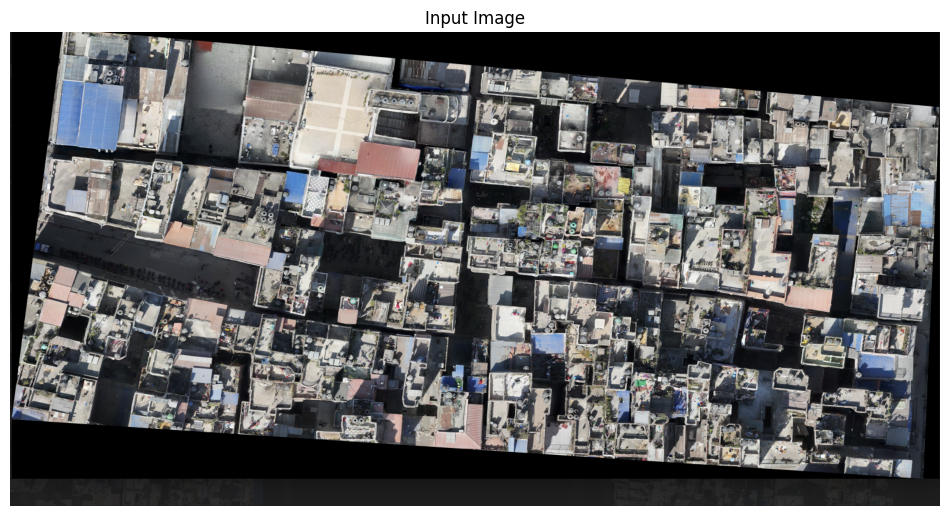

Generating masks... This may take a few minutes.
Number of masks generated: 582


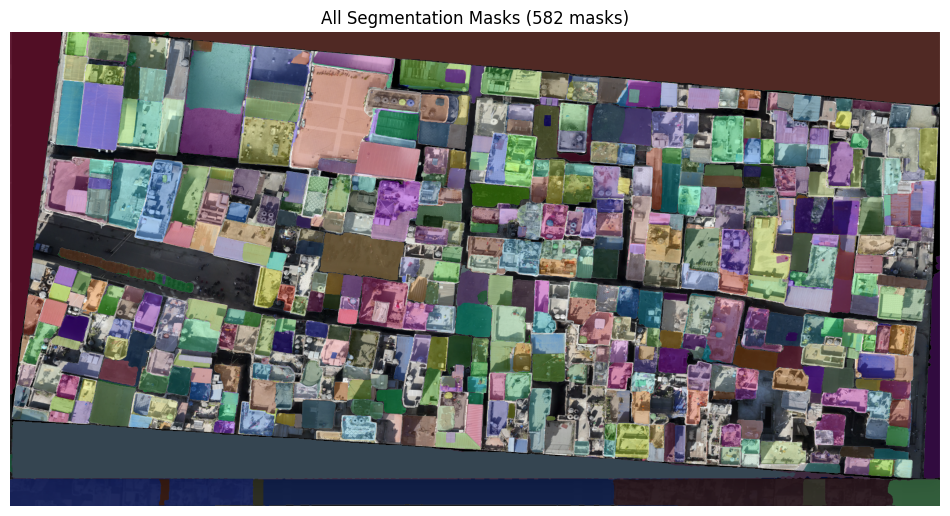

Filtered to 510 potential building masks


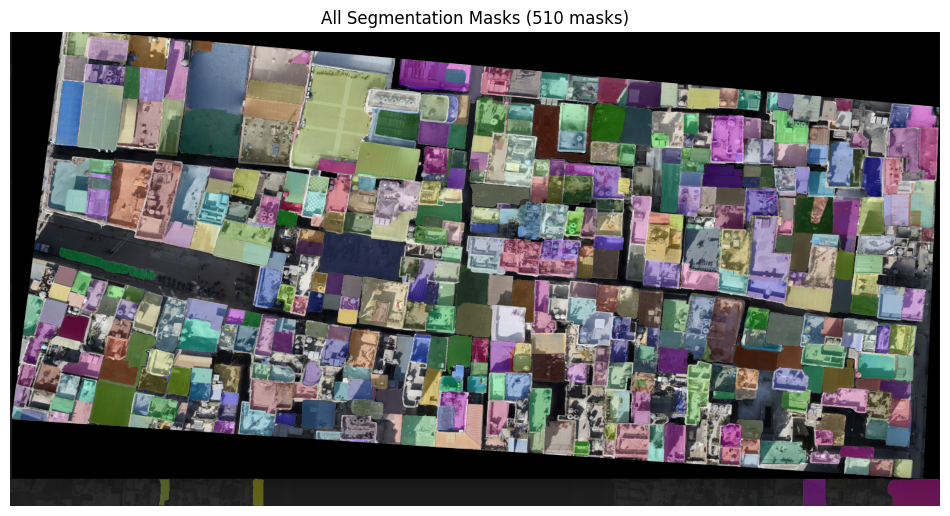

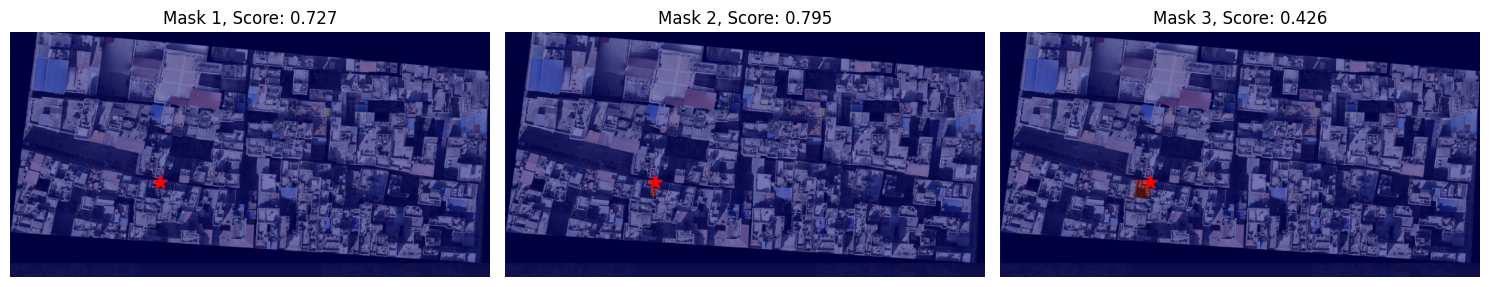

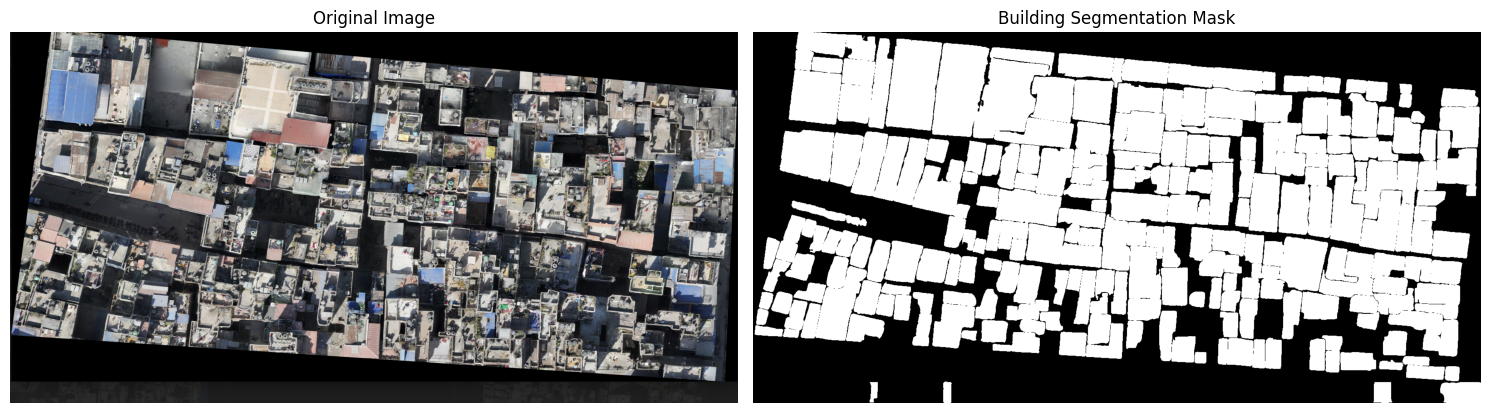

Binary mask saved as 'building_mask.png'
Created 501 building polygons
                                            geometry  area  id
0  POLYGON ((1008 375, 1006 386, 1004 424, 1046 4...  2186   0
1  POLYGON ((932 520, 899 522, 898 525, 899 534, ...  2017   1
2  POLYGON ((1312 484, 1309 491, 1305 521, 1303 5...  3145   2
3  POLYGON ((1388 349, 1384 352, 1384 357, 1382 3...   904   3
4  POLYGON ((1348 439, 1343 440, 1341 455, 1339 4...  2831   4
Polygons saved as 'buildings.geojson'


/usr/local/lib/python3.12/dist-packages/pyogrio/geopandas.py:917: UserWarning: 'crs' was not provided.  The output dataset will not have projection information defined and may not be usable in other systems.
  write(


interactive(children=(IntSlider(value=500, description='min_area', max=10000, min=100, step=100), IntSlider(va…


=== Building Segmentation Complete! ===
Total masks found: 582
Building masks after filtering: 510

You can now:
1. Adjust filtering parameters using the interactive widget above
2. Download the binary mask and GeoJSON files
3. Import the GeoJSON into QGIS for further analysis


In [ ]:
from ipywidgets import interact, IntSlider

@interact(
    min_area=IntSlider(min=100, max=10000, step=100, value=500),
    max_area=IntSlider(min=1000, max=100000, step=1000, value=50000),
    min_aspect=IntSlider(min=0.1, max=2.0, step=0.1, value=0.3),
    max_aspect=IntSlider(min=1.0, max=5.0, step=0.1, value=3.0)
)
def interactive_filter(min_area, max_area, min_aspect, max_aspect):
    """Interactively adjust filtering parameters"""
    filtered = filter_building_masks(
        masks,
        min_area=min_area,
        max_area=max_area,
        aspect_ratio_range=(min_aspect, max_aspect)
    )
    print(f"Number of buildings: {len(filtered)}")
    show_anns(filtered, figsize=(10, 6))

print("\n=== Building Segmentation Complete! ===")
print(f"Total masks found: {len(masks)}")
print(f"Building masks after filtering: {len(building_masks)}")
print("\nYou can now:")
print("1. Adjust filtering parameters using the interactive widget above")
print("2. Download the binary mask and GeoJSON files")
print("3. Import the GeoJSON into QGIS for further analysis")